In [18]:
import sys
from pathlib import Path


PROJECT_ROOT = Path(r"C:\Users\Sherif\Desktop\ECG analysis")

sys.path.insert(0, str(PROJECT_ROOT))

In [19]:
import importlib
import src.train_autoencoder

importlib.reload(src.train_autoencoder)

import torch
import matplotlib.pyplot as plt

from models.UNet1D import UNet1D
from src.dataset import create_dataloaders
from src.train_autoencoder import train_autoencoder, test_autoencoder

In [20]:
import random
import numpy as np
import pandas as pd

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # pour reproductibilité (important)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [21]:
train_loader, val_loader, test_loader, label_cols, _ = create_dataloaders()

In [22]:
model = UNet1D(in_channels=1, out_channels=12, embedding_dim=32)

In [23]:
train_autoencoder(
    model,
    train_loader,
    val_loader,
    epochs=40,
    lr=1e-3
)


Epoch 1/40


Training AE:   0%|          | 0/545 [00:00<?, ?it/s]

Evaluating AE: 100%|██████████| 69/69 [01:03<00:00,  1.08it/s]


Train Loss (MSE): 0.4367
Val MSE: 0.4214
Val Corr: 0.7410

Epoch 2/40


Evaluating AE: 100%|██████████| 69/69 [00:41<00:00,  1.65it/s]


Train Loss (MSE): 0.4019
Val MSE: 0.4147
Val Corr: 0.7467

Epoch 3/40


... (72 outputs left out)

Evaluating AE: 100%|██████████| 69/69 [00:47<00:00,  1.44it/s]


Train Loss (MSE): 0.2540
Val MSE: 0.4283
Val Corr: 0.7478

Epoch 40/40


Evaluating AE: 100%|██████████| 69/69 [00:47<00:00,  1.47it/s]

Train Loss (MSE): 0.2499
Val MSE: 0.4284
Val Corr: 0.7466


In [97]:
test_autoencoder(model, test_loader)

KeyboardInterrupt: 

In [24]:
def fast_test(model, loader, device="cpu"):
    model.eval()
    total_mse = 0
    total_corr = 0
    n = 0

    with torch.no_grad():
        for signals, _ in loader:

            signals = signals.to(device)
            input_lead = signals[:, 0:1, :]
            target = signals

            pred, _ = model(input_lead)

            mse = torch.mean((pred - target)**2)

            x = pred - pred.mean(dim=-1, keepdim=True)
            y = target - target.mean(dim=-1, keepdim=True)

            corr = torch.sum(x*y, dim=-1) / (
                torch.sqrt(torch.sum(x**2, dim=-1) * torch.sum(y**2, dim=-1) + 1e-8)
            )

            total_mse += mse.item()
            total_corr += corr.mean().item()
            n += 1

    print("MSE:", total_mse/n)
    print("Corr:", total_corr/n)
fast_test(model, test_loader)

MSE: 0.4274613110051639
Corr: 0.7471326425455619


i have looked at this paper for the input lead analysis : https://arxiv.org/html/2502.00559v2

In [25]:
# analyzing (maybe) how leads affect reconstruction
def test_input_leads(model, loader, device="cpu"):

    results = []

    for lead_idx in range(12):

        total_mse = 0
        n = 0

        for signals, _ in loader:

            signals = signals.to(device)

            input_lead = signals[:, lead_idx:lead_idx+1, :]
            target = signals

            pred, _ = model(input_lead)

            mse = torch.mean((pred - target)**2)

            total_mse += mse.item()
            n += 1

        avg_mse = total_mse / n
        results.append(avg_mse)

        print(f"Lead {lead_idx} → MSE: {avg_mse:.4f}")

    return results

results = test_input_leads(model, test_loader) 

Lead 0 → MSE: 0.4275
Lead 1 → MSE: 0.8049
Lead 2 → MSE: 1.4847
Lead 3 → MSE: 1.7404
Lead 4 → MSE: 0.5947
Lead 5 → MSE: 1.1306
Lead 6 → MSE: 1.6304
Lead 7 → MSE: 1.2439
Lead 8 → MSE: 0.9526
Lead 9 → MSE: 0.7736
Lead 10 → MSE: 0.6788
Lead 11 → MSE: 0.6666


In [27]:
def test_output_leads(model, loader, device="cpu"):

    total_mse = torch.zeros(12)
    n = 0

    for signals, _ in loader:

        signals = signals.to(device)
        input_lead = signals[:, 0:1, :]
        target = signals

        pred, _ = model(input_lead)

        mse = ((pred - target)**2).mean(dim=(0,2))  # par lead

        total_mse += mse.cpu()
        n += 1

    final = total_mse / n

    for i in range(12):
        print(f"Output lead {i}: {final[i]:.4f}")

    return final

output_results = test_output_leads(model, test_loader)

Output lead 0: 0.0022
Output lead 1: 0.5482
Output lead 2: 0.7752
Output lead 3: 0.2030
Output lead 4: 0.3160
Output lead 5: 0.8537
Output lead 6: 0.3737
Output lead 7: 0.4129
Output lead 8: 0.4661
Output lead 9: 0.4082
Output lead 10: 0.3671
Output lead 11: 0.4033


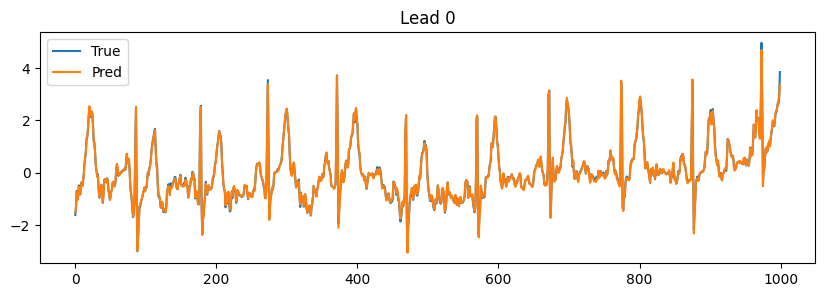

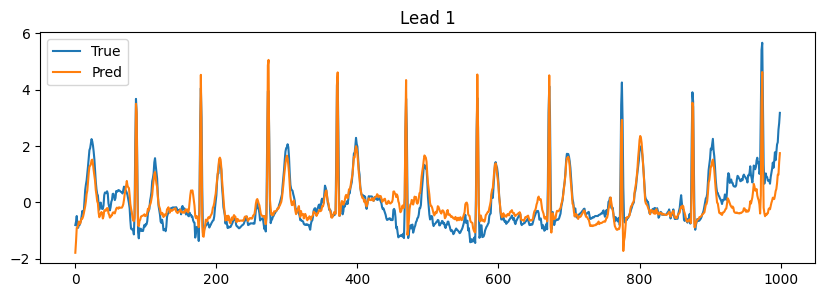

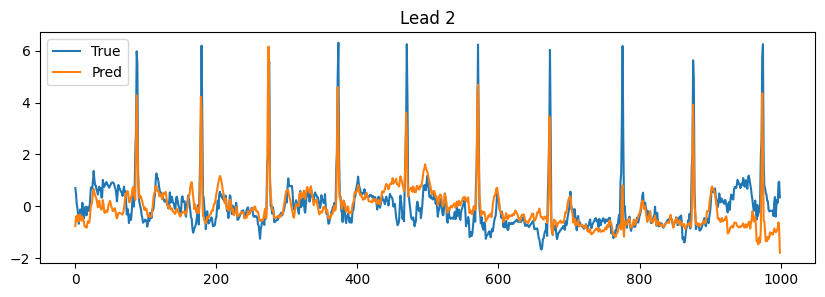

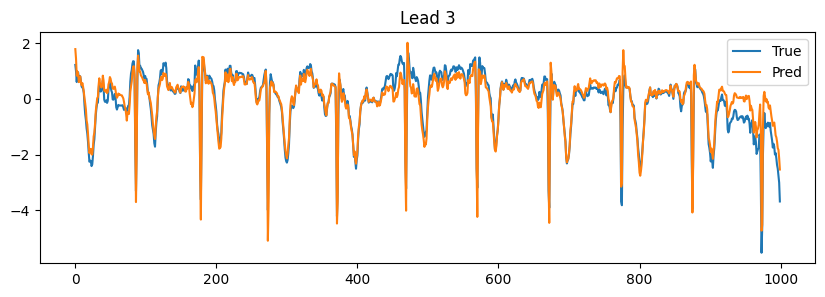

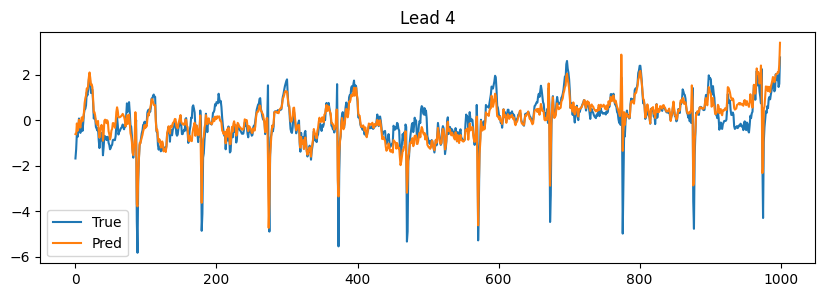

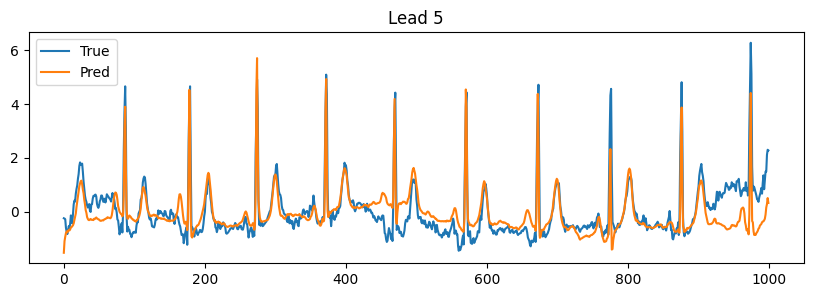

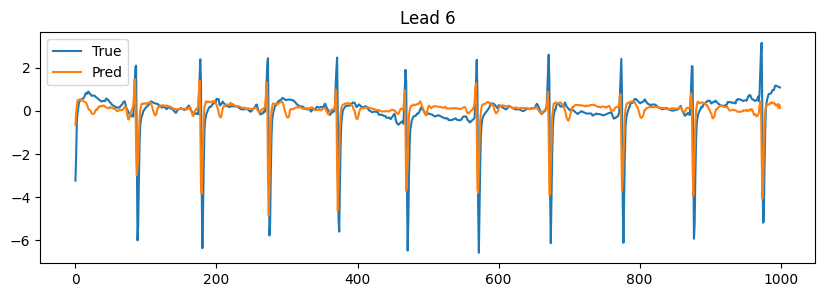

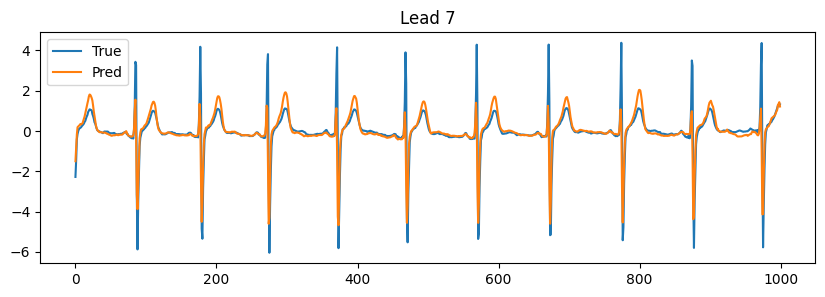

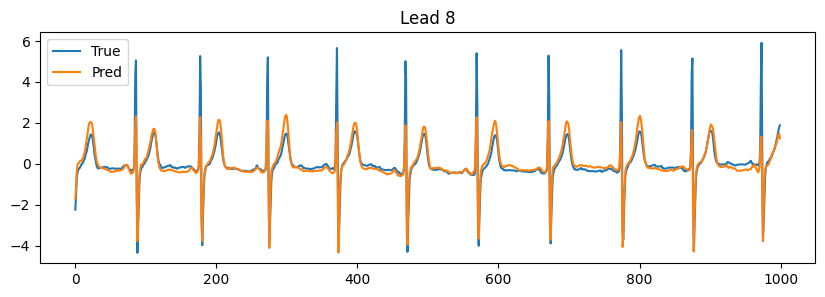

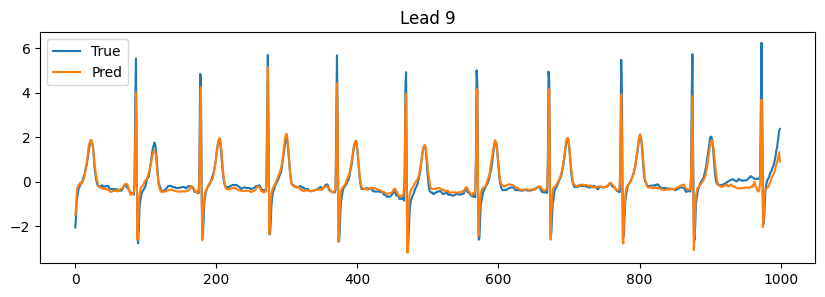

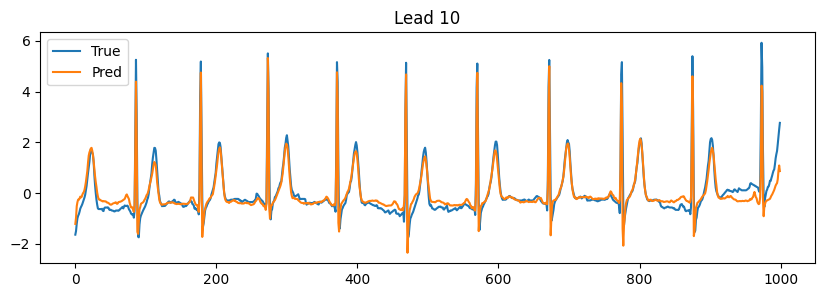

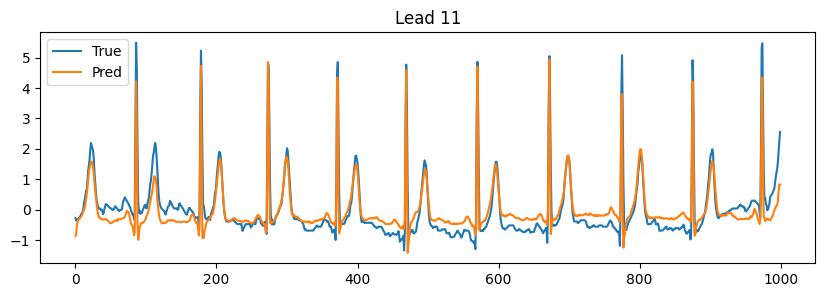

In [92]:
# some examples of signal vs reconstructed 
signals, _ = next(iter(test_loader))
signals = signals[:1].to("cpu")

input_lead = signals[:, 0:1, :]
target = signals

pred, _ = model(input_lead)

pred = pred.detach().cpu()
target = target.cpu()

for lead in [i for i in range(12)]:

    plt.figure(figsize=(10,3))
    plt.plot(target[0, lead], label="True")
    plt.plot(pred[0, lead], label="Pred")
    plt.title(f"Lead {lead}")
    plt.legend()
    plt.show()

In [43]:
import torch
import numpy as np

all_embeddings = []
all_labels = []

model.eval()

with torch.no_grad():
    for signals, labels in test_loader:

        signals = signals.to("cpu")

        input_lead = signals[:, 0:1, :]
        _, embeddings = model(input_lead)

        B = embeddings.shape[0]
        E = embeddings.view(B, -1)  # (B, 12*d)

        all_embeddings.append(E.cpu())
        all_labels.append(labels)

X = torch.cat(all_embeddings).numpy()
y = torch.cat(all_labels).numpy()

print("Embeddings shape:", X.shape)
print("Labels shape:", y.shape)

Embeddings shape: (2198, 384)
Labels shape: (2198, 5)


In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA → réduit bruit + accélère
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X_scaled)

print("After PCA:", X_pca.shape)

After PCA: (2198, 50)


#### Embedding analysis via t-sne & UMAP

In [93]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate=200,
    #n_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_pca)

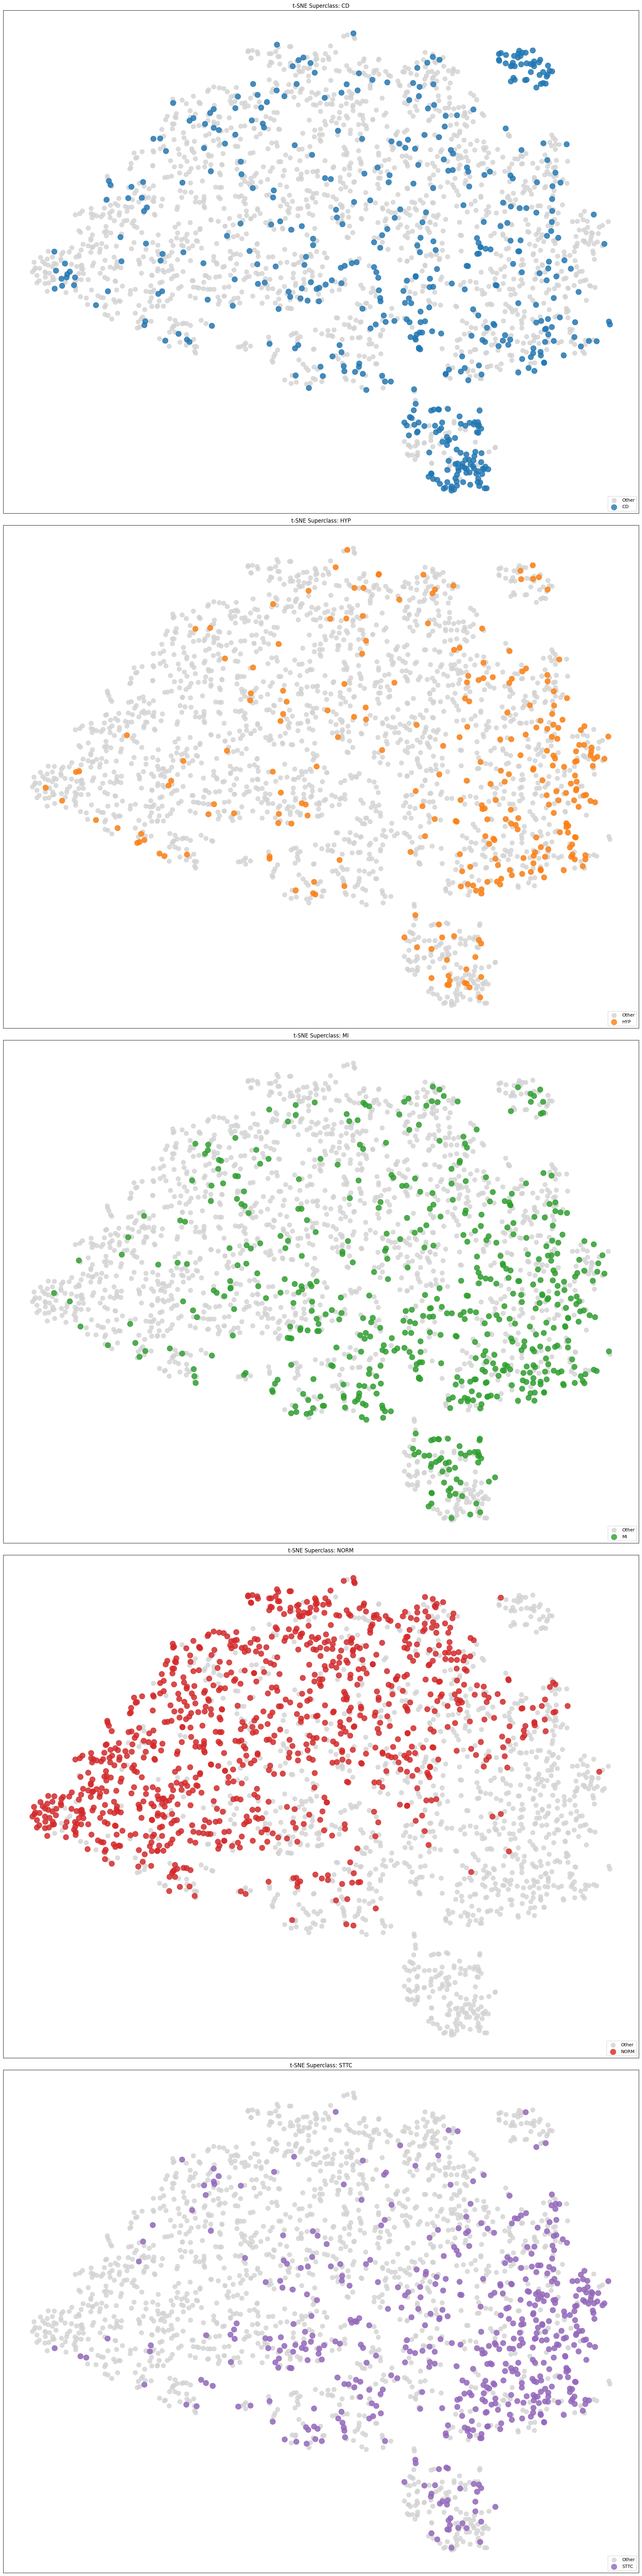

In [94]:
import matplotlib.pyplot as plt

superclasses = ["CD", "HYP", "MI", "NORM", "STTC"]
fig, axes = plt.subplots(5, 1, figsize=(20, 80), sharex=True, sharey=True)

for i, sc in enumerate(superclasses):
    
    axes[i].scatter(X_tsne[:, 0], X_tsne[:, 1], c='lightgray', alpha=0.8, s=100, label='Other')
    
    
    mask = y_array[:, i] == 1
    axes[i].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=f'C{i}', alpha=0.8, s=150, label=sc)
    
    axes[i].set_title(f"t-SNE Superclass: {sc}")
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].legend(loc='lower right')

plt.tight_layout()
plt.show()


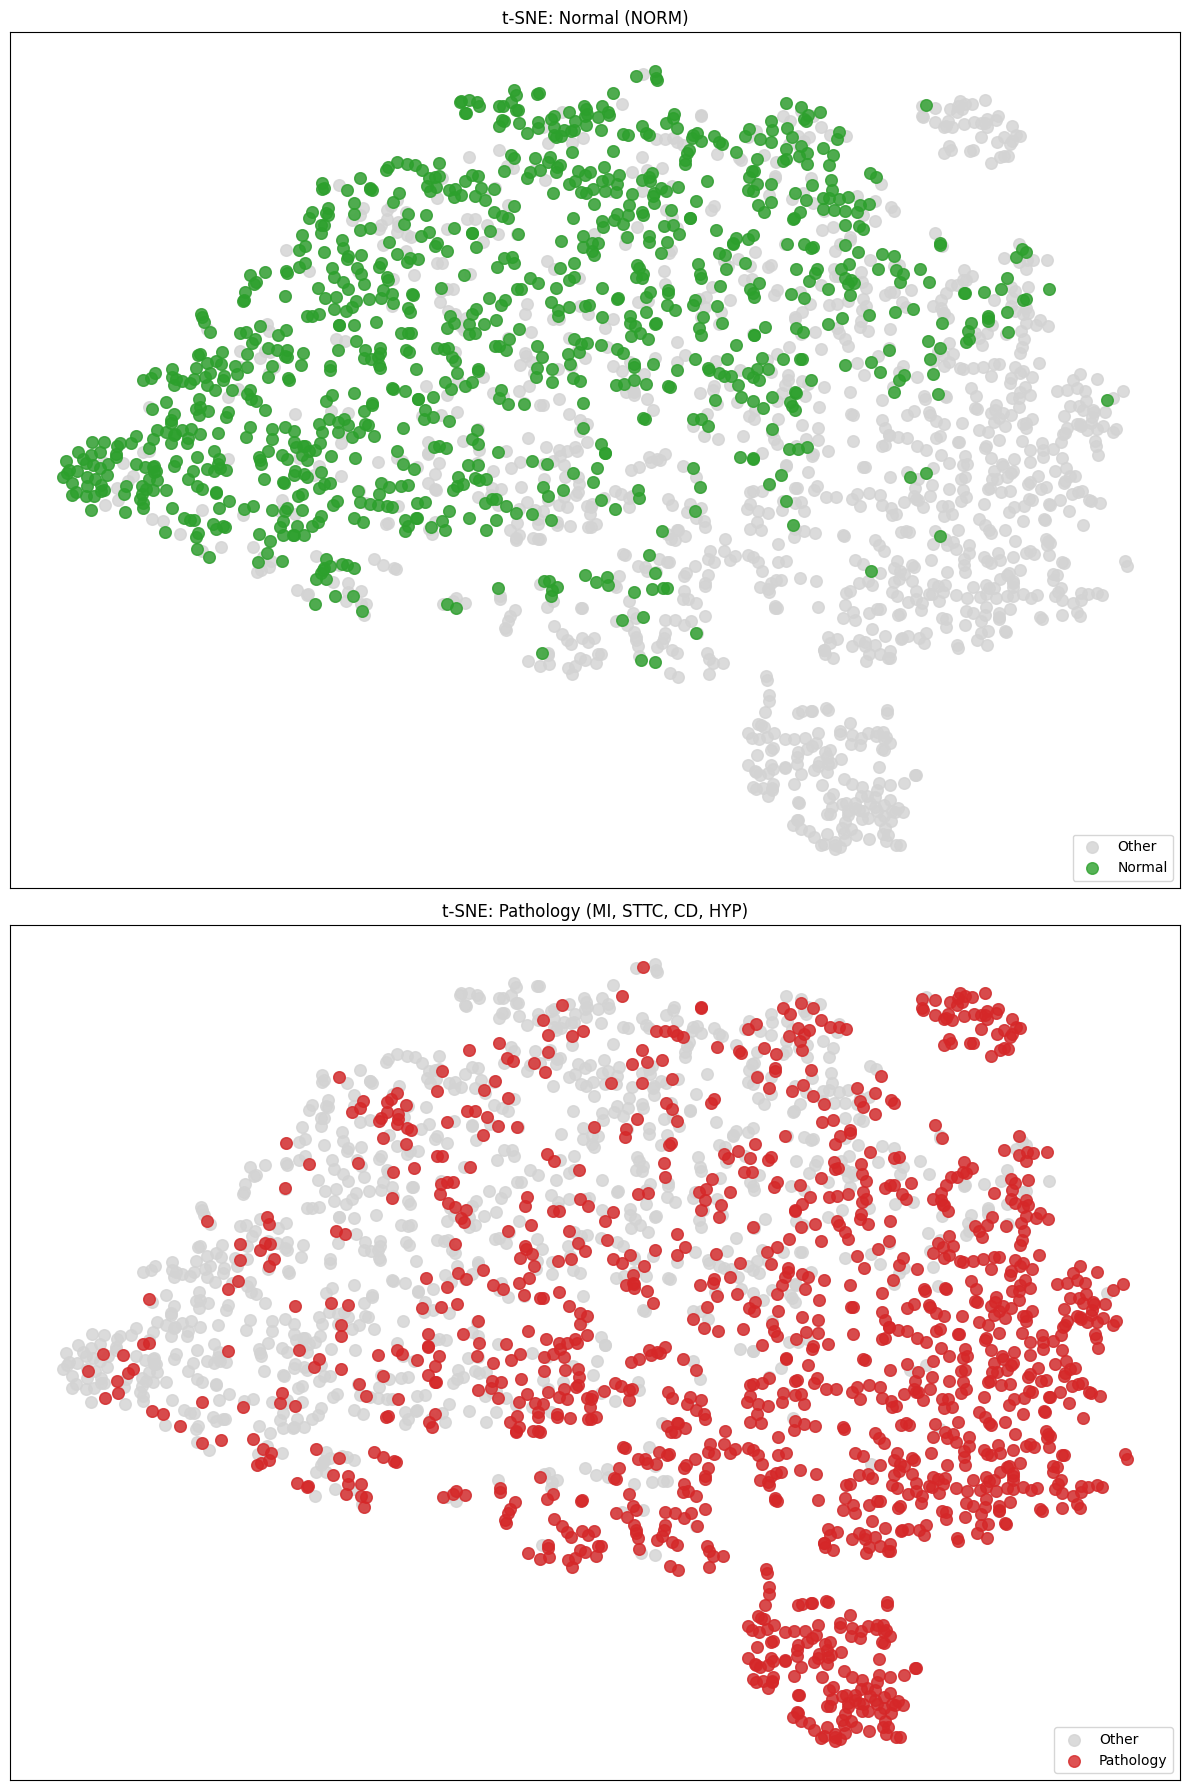

In [96]:
fig, axes = plt.subplots(2, 1, figsize=(12, 18), sharex=True, sharey=True)

mask_norm = y_array[:, 3] == 1
mask_pathology = y_array[:, 3] == 0  

# --- 1) Normal ---
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c='lightgray', alpha=0.8, s=70, label='Other')
axes[0].scatter(X_tsne[mask_norm, 0], X_tsne[mask_norm, 1], c='C2', alpha=0.8, s=70, label='Normal')
axes[0].set_title("t-SNE: Normal (NORM)")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].legend(loc='lower right')

# --- 2) Pathology ---
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c='lightgray', alpha=0.8, s=70, label='Other')
axes[1].scatter(X_tsne[mask_pathology, 0], X_tsne[mask_pathology, 1], c='C3', alpha=0.8, s=70, label='Pathology')
axes[1].set_title("t-SNE: Pathology (MI, STTC, CD, HYP)")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


In [47]:
import umap.umap_ as umap

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=42
)

X_umap = reducer.fit_transform(X_pca)

c:\Users\Sherif\Desktop\ECG analysis\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


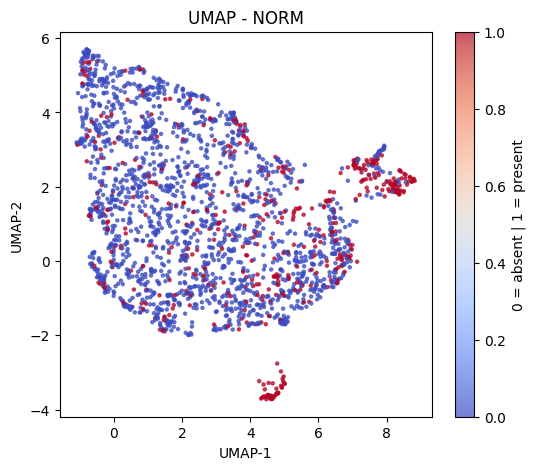

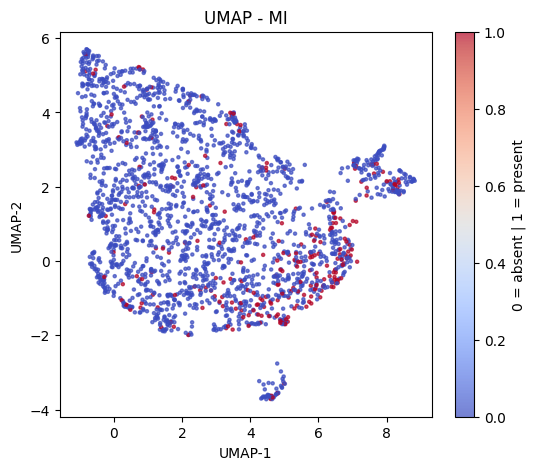

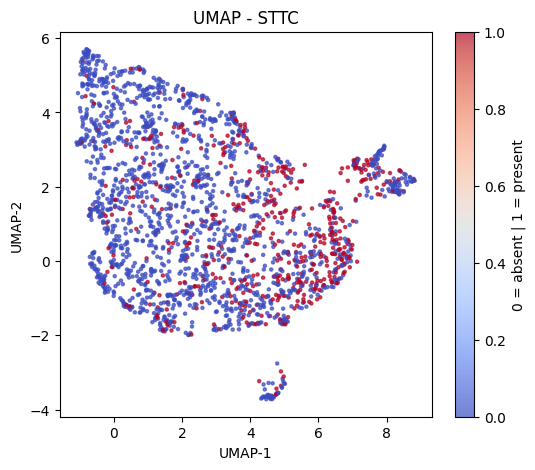

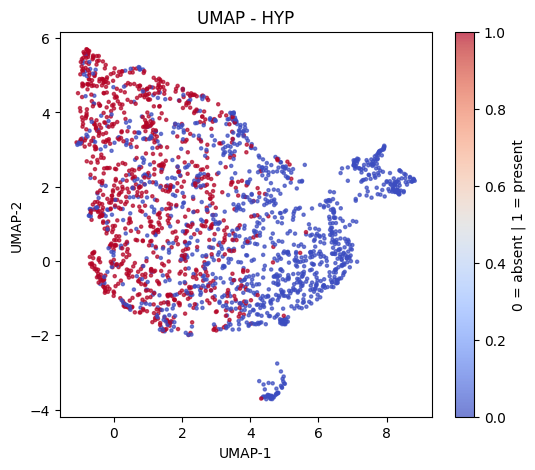

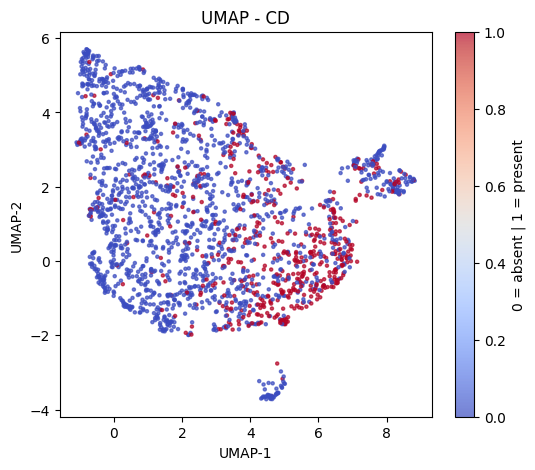

In [48]:
import matplotlib.pyplot as plt

class_names = ["NORM", "MI", "STTC", "HYP", "CD"]

for i, name in enumerate(class_names):

    plt.figure(figsize=(6,5))

    plt.scatter(
        X_umap[:,0],
        X_umap[:,1],
        c=y[:, i],
        cmap="coolwarm",
        s=5,
        alpha=0.7
    )

    plt.colorbar(label="0 = absent | 1 = present")
    plt.title(f"UMAP - {name}")
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.show()

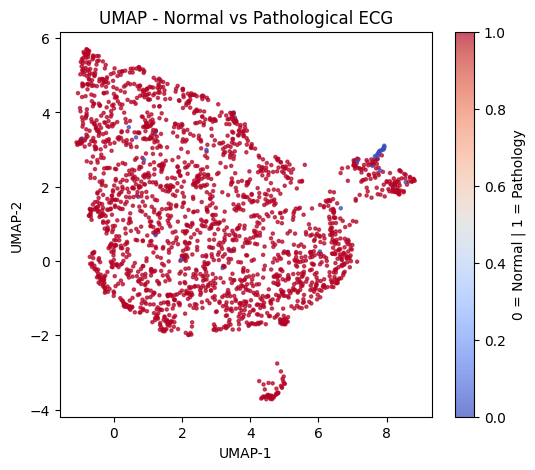

In [49]:
binary_labels = (y.sum(axis=1) > 0).astype(int)

plt.figure(figsize=(6,5))

plt.scatter(
    X_umap[:,0],
    X_umap[:,1],
    c=binary_labels,
    cmap="coolwarm",
    s=5,
    alpha=0.7
)

plt.colorbar(label="0 = Normal | 1 = Pathology")
plt.title("UMAP - Normal vs Pathological ECG")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()

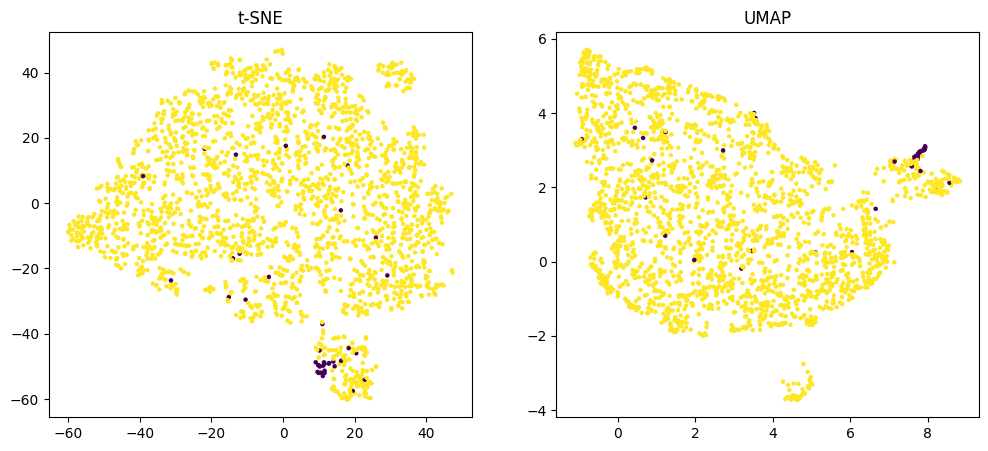

In [50]:
fig, axs = plt.subplots(1,2, figsize=(12,5))

axs[0].scatter(X_tsne[:,0], X_tsne[:,1], c=binary_labels, s=5)
axs[0].set_title("t-SNE")

axs[1].scatter(X_umap[:,0], X_umap[:,1], c=binary_labels, s=5)
axs[1].set_title("UMAP")

plt.show()

In [52]:
torch.save(model.state_dict(), "unet_ecg.pth")

In [55]:
import ast
import pandas as pd

df = pd.read_csv("../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/ptbxl_database.csv")
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

In [56]:
def extract_subclasses(scp_dict):
    return list(scp_dict.keys())

df["subclasses"] = df["scp_codes"].apply(extract_subclasses)

In [57]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
y_sub = mlb.fit_transform(df["subclasses"])

In [62]:
print(len(mlb.classes_), "subclasses")

71 subclasses


In [59]:
scp = pd.read_csv("../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/scp_statements.csv", index_col=0)

valid_diag = scp[scp.diagnostic == 1].index

In [60]:
def filter_diag_subclasses(scp_dict):
    return [k for k in scp_dict.keys() if k in valid_diag]

df["subclasses"] = df["scp_codes"].apply(filter_diag_subclasses)

In [75]:
df["subclasses"].value_counts

<bound method IndexOpsMixin.value_counts of 0         [NORM]
1         [NORM]
2         [NORM]
3         [NORM]
4         [NORM]
          ...   
21794      [NDT]
21795     [NORM]
21796    [ISCAS]
21797     [NORM]
21798     [NORM]
Name: subclasses, Length: 21799, dtype: object>

In [61]:
df.head(5)

,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,subclasses
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,[NORM]
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,[NORM]
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,[NORM]
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,[NORM]
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,[NORM]


In [ ]:
# since i used strat fold
test_df = df[df["strat_fold"] == 10]  
y_sub_test = mlb.transform(test_df["subclasses"])

In [ ]:
import matplotlib.pyplot as plt

def plot_one_class(X, y, class_idx, class_name):
    
    plt.figure(figsize=(6,5))

    
    plt.scatter(X[:,0], X[:,1], color="lightgray", s=5, alpha=0.3)

    # label in red 
    idx = y[:, class_idx] == 1
    plt.scatter(X[idx,0], X[idx,1], color="red", s=8, label=class_name)

    plt.legend()
    plt.title(f"UMAP - {class_name}")
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.show()

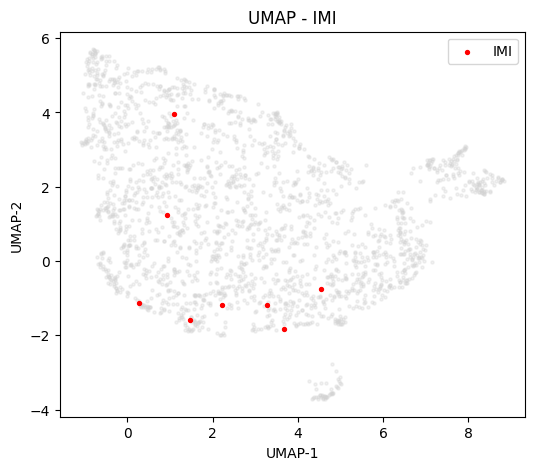

In [68]:
plot_one_class(X_umap, y_sub_test, i, "IMI")

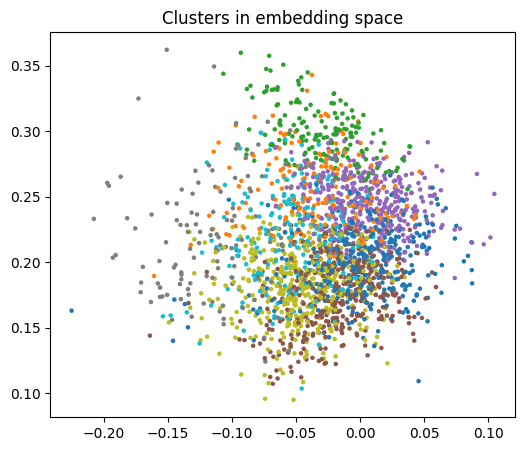

In [76]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=8)
clusters = kmeans.fit_predict(X)

plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:,1], c=clusters, cmap="tab10", s=5)
plt.title("Clusters in embedding space")
plt.show()

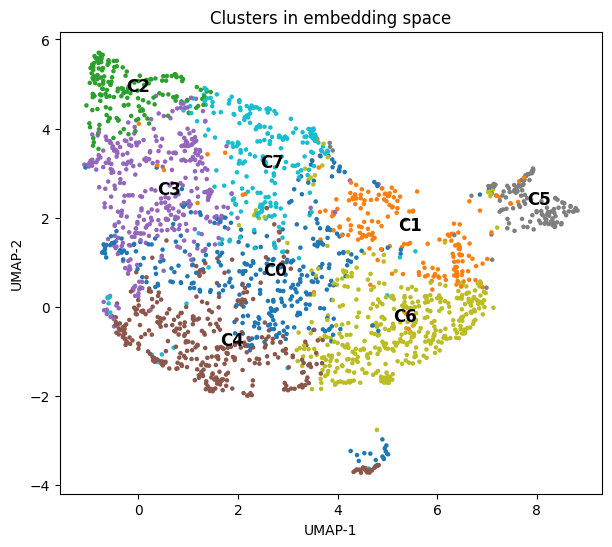

In [79]:
plt.figure(figsize=(7,6))

plt.scatter(X_umap[:,0], X_umap[:,1], c=clusters, cmap="tab10", s=5)

# centroids
centroids = np.array([
    X_umap[clusters == c].mean(axis=0)
    for c in range(8)
])

for i, (x, y) in enumerate(centroids):
    plt.text(x, y, f"C{i}", fontsize=12, weight='bold')

plt.title("Clusters in embedding space")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()

In [78]:
# analyse composition
subclass_names = mlb.classes_

for c in range(8):
    print(f"\n===== Cluster {c} =====")

    cluster_data = y_sub_test[clusters == c]
    mean_vals = cluster_data.mean(axis=0)

    # garder les subclasses importantes
    for i in np.argsort(mean_vals)[::-1][:5]:  # top 5
        if mean_vals[i] > 0.05:  # seuil
            print(f"{subclass_names[i]}: {mean_vals[i]:.2f}")


===== Cluster 0 =====
NORM: 0.44
IMI: 0.16
LAFB: 0.10
NDT: 0.10
ASMI: 0.07

===== Cluster 1 =====
ASMI: 0.35
IMI: 0.18
LAFB: 0.12
LVH: 0.11
ISCAL: 0.11

===== Cluster 2 =====
NORM: 0.84
IRBBB: 0.06

===== Cluster 3 =====
NORM: 0.75
IRBBB: 0.06
IMI: 0.05

===== Cluster 4 =====
NORM: 0.61
IMI: 0.10
LVH: 0.08
LAFB: 0.06
NDT: 0.06

===== Cluster 5 =====
CLBBB: 0.37
ASMI: 0.24
LAFB: 0.19
LVH: 0.11
ISC_: 0.09

===== Cluster 6 =====
LVH: 0.27
IMI: 0.23
ISC_: 0.22
ASMI: 0.21
NDT: 0.18

===== Cluster 7 =====
NORM: 0.57
NDT: 0.09
IMI: 0.09
LVH: 0.06


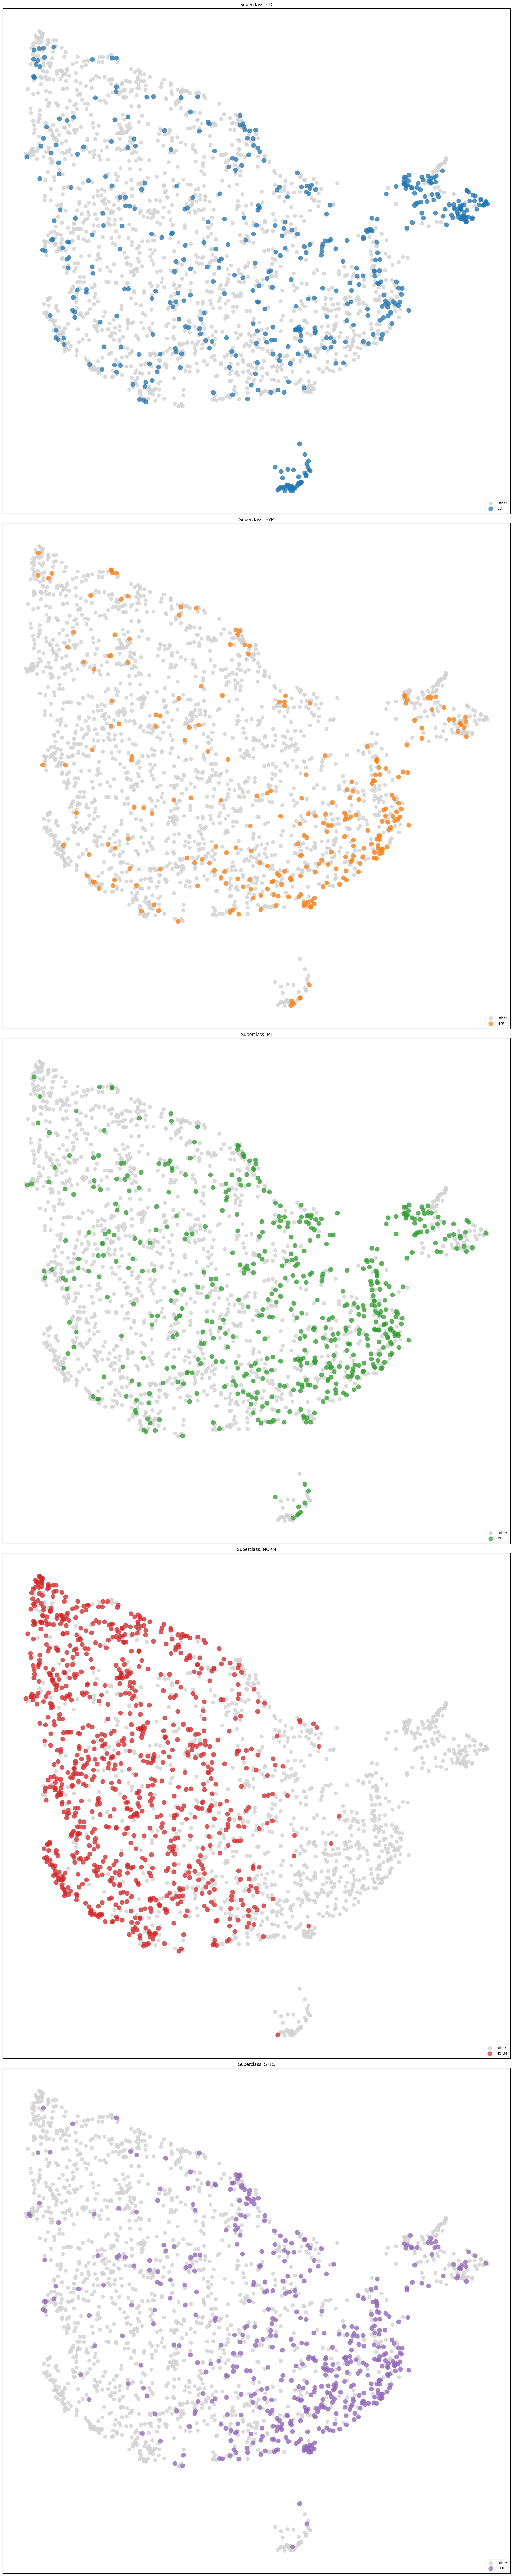

In [88]:
import matplotlib.pyplot as plt
import numpy as np

superclasses = ["CD", "HYP", "MI", "NORM", "STTC"]
fig, axes = plt.subplots(5, 1, figsize=(20, 100), sharex=True, sharey=True)


if isinstance(all_labels, list):
    try:
        y_array = np.concatenate(all_labels, axis=0)
    except ValueError:
        y_array = np.array(all_labels)
else:
    y_array = all_labels

for i, sc in enumerate(superclasses):
    axes[i].scatter(X_umap[:, 0], X_umap[:, 1], c='lightgray', alpha=0.8, s=100, label='Other')
    
    
    mask = y_array[:, i] == 1
    axes[i].scatter(X_umap[mask, 0], X_umap[mask, 1], c=f'C{i}', alpha=0.7, s=150, label=sc)
    
    axes[i].set_title(f"Superclass: {sc}")
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].legend(loc='lower right')

plt.tight_layout()
plt.show()


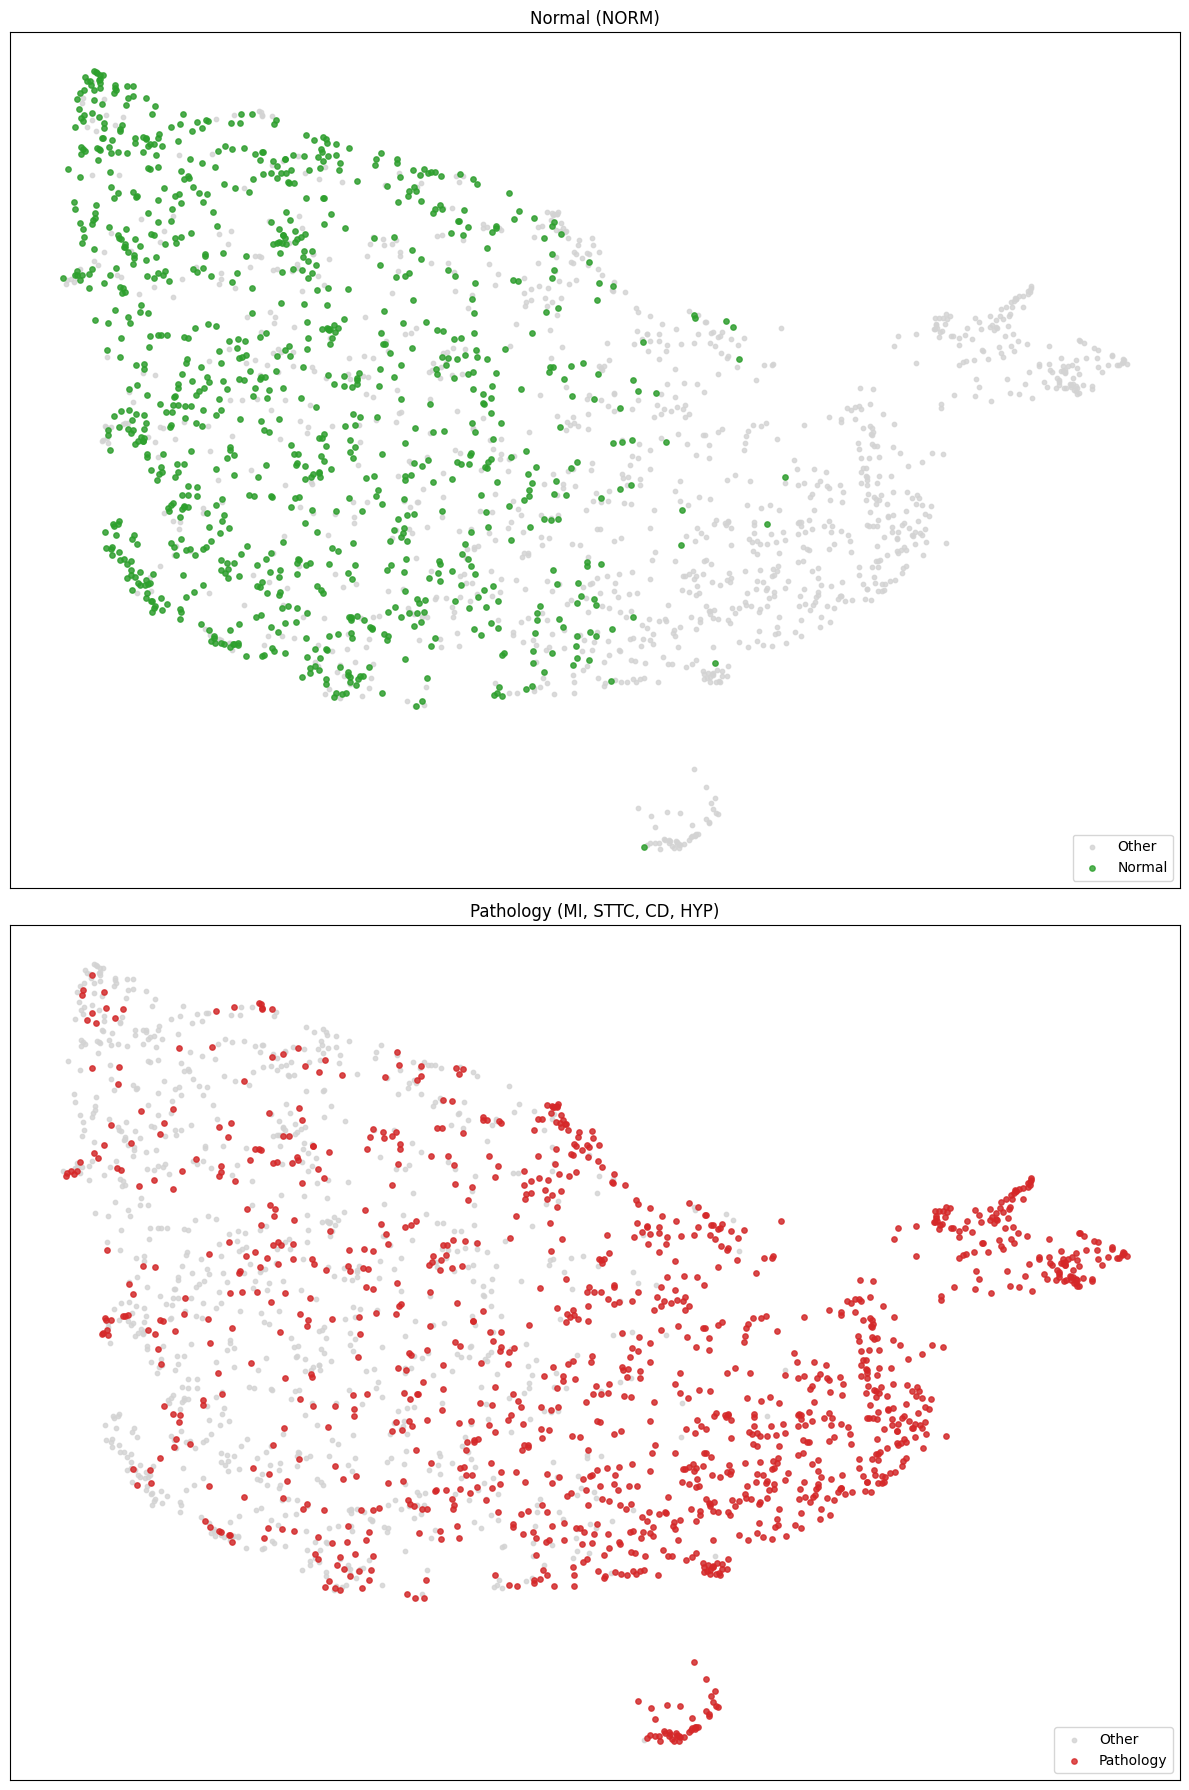

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 18), sharex=True, sharey=True)

mask_norm = y_array[:, 3] == 1
mask_pathology = y_array[:, 3] == 0  

# Normal 
axes[0].scatter(X_umap[:, 0], X_umap[:, 1], c='lightgray', alpha=0.8, s=10, label='Other')
axes[0].scatter(X_umap[mask_norm, 0], X_umap[mask_norm, 1], c='C2', alpha=0.8, s=15, label='Normal')
axes[0].set_title("Normal (NORM)")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].legend(loc='lower right')

# Pathology 
axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c='lightgray', alpha=0.8, s=10, label='Other')
axes[1].scatter(X_umap[mask_pathology, 0], X_umap[mask_pathology, 1], c='C3', alpha=0.8, s=15, label='Pathology')
axes[1].set_title("Pathology (MI, STTC, CD, HYP)")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()
